In [1]:
LEAGUE = 'eredivisie'
DATA_ROOT = '/Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/data'
RESULTS_ROOT = '/Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full'
IMAGES_ROOT = '/Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/images'
B_OVERRIDE = 1000

Full analysis of 1 Kalshi football league

Run for a single league (set `LEAGUE` below), or use `run_all_leagues.ipynb` to run it in a fresh kernel for all 9 leagues -> 
`cross_league_analysis.ipynb` then pools the results. Inputs read from `data/<league>/` and never modified; tables go to
`results/full/<league>/` and figs to `images/`.

Sections: 0 data prep · 1 contract mechanics · 2 no-arb bundles + fees · 3 calibration + scoring ·
4 deviations, liquidity + hourly arb scan · 5 robustness, power + multiple testing · per-league summary.

Limitations: horizons anchored to Kalshi's expected expiration (≈ kickoff + 3h), not an independently verified kickoff time;
hourly candles give closing quotes but no depth or fills; 0.07 fee coeff modelled for the whole sample; `R = 0.04` is a fixed
discounting assumption.

In [2]:
from pathlib import Path
LEAGUE = globals().get("LEAGUE", "epl")
DATA_ROOT = Path(globals().get("DATA_ROOT", (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()) / "data"))
RESULTS_ROOT = Path(globals().get("RESULTS_ROOT", (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()) / "results" / "full"))
IMAGES_ROOT = Path(globals().get("IMAGES_ROOT", (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()) / "images"))  # every fig, ready for the report
B_OVERRIDE = globals().get("B_OVERRIDE", 300)  # 1000 for final paper bootstrap precision
RESULT_DIR = RESULTS_ROOT / LEAGUE
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("League:", LEAGUE, "| input:", (DATA_ROOT / LEAGUE).resolve(), "| output:", RESULT_DIR.resolve())

League: eredivisie | input: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/data/eredivisie | output: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full/eredivisie


Theory in brief

Each match has 3 mutually exclusive, exhaustive outcomes; a YES contract pays \$1 if its outcome occurs. Holding 1 YES on each
outcome pays \$1 for sure and holding 1 NO on each pays \$2 -> w/o frictions the 3 YES prices must sum to the PV
of \$1. With a bid-ask spread + fees, no arb only requires $\sum \text{bid} \le e^{-r\tau} \le \sum \text{ask}$ up to fees.
Prices = real-world Pr only if, on top of that, traders are risk neutral, discounting is negligible and there are no frictions.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm, chi2

R = 0.04  # annual rf rate, continuous compounding
FEE_RATE = 0.07  # Kalshi taker fee = round up(M * 0.07 * C * P * (1-P)). KXEPLGAME not in the non-standard
                 # list of the fee schedule eff. 7 July 2026 -> M = 1 (kalshi.com/docs/kalshi-fee-schedule.pdf)
LEGS = ["home", "draw", "away"]
HORIZONS = {"1d": 24, "7d": 168}  # hours b4 Kalshi's expected expiration (≈ kickoff + 3h)
MAX_QUOTE_AGE_MIN = 360  # drop a quote older than 6h at target time (section 0: any cap in [150, 930) gives same sample)
B = B_OVERRIDE  # bootstrap repl
SEED = 456
BINS = np.linspace(0, 1, 11)  # 10 equal-width Pr bins
# EPL-only BIG_SIX removed, same general drivers for every league

def kalshi_fee(price):
    # taker fee for a 1-contract order, in $, rounded up to the cent (Kalshi's 1-contract table)
    return np.ceil(100 * FEE_RATE * price * (1 - price)) / 100

logit = lambda p: np.log(np.clip(p, 1e-8, 1 - 1e-8) / (1 - np.clip(p, 1e-8, 1 - 1e-8)))

def fit_logit(x, y, iters=50):
    # unpenalized logit of y on [1, x] via Newton-Raphson -> returns (a, b)
    Z = np.column_stack([np.ones_like(x), x])
    beta = np.zeros(2)
    for _ in range(iters):
        mu = 1 / (1 + np.exp(-Z @ beta))
        step = np.linalg.solve(Z.T @ (Z * (mu * (1 - mu))[:, None]), Z.T @ (y - mu))
        beta += step
        if np.abs(step).max() < 1e-10:
            break
    return beta

def cluster_bootstrap(data, stat, B=B, seed=SEED):
    # resample whole matches (event_ticker) w/ replacement, return the B values of stat(sample)
    rng = np.random.default_rng(seed)
    rows_by_match = list(data.groupby("event_ticker").indices.values())
    out = []
    for _ in range(B):
        picks = rng.integers(0, len(rows_by_match), len(rows_by_match))
        out.append(stat(data.iloc[np.concatenate([rows_by_match[i] for i in picks])]))
    return np.array(out)

def reliability(d, col="p"):
    # reliability table: count, avg price + realized YES freq in each Pr bin
    b = pd.cut(d[col], BINS, include_lowest=True)
    return d.groupby(b, observed=False).agg(n=("y", "size"), avg_price=(col, "mean"), freq_yes=("y", "mean"))

def reliability_term(p, y, bins):
    # miscalibration term of the Murphy decomposition for a given binning
    t = pd.DataFrame({"p": p, "y": y}).groupby(pd.cut(p, bins, include_lowest=True), observed=True).agg(
        n=("y", "size"), p=("p", "mean"), f=("y", "mean"))
    return (t["n"] * (t["p"] - t["f"]) ** 2).sum() / len(p)

def brier(p, y):
    return np.mean((p - y) ** 2)

def log_loss(p, y):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def murphy(d, col="p"):
    # Murphy decomposition w/ BINS: Brier ≈ reliability - resolution + uncertainty
    t = reliability(d, col).dropna(subset=["avg_price"])
    N, ybar = len(d), d["y"].mean()
    rel = (t["n"] * (t["avg_price"] - t["freq_yes"]) ** 2).sum() / N
    res = (t["n"] * (t["freq_yes"] - ybar) ** 2).sum() / N
    return rel, res, ybar * (1 - ybar)

def ols_cluster(y, Xmat, groups):
    # OLS w/ intercept + CR1 cluster-robust SEs -> returns (beta, se, R^2)
    Z = np.column_stack([np.ones(len(Xmat)), Xmat])
    n, k = Z.shape
    ZtZ_inv = np.linalg.pinv(Z.T @ Z)  # tolerate redundant drivers, check rank/VIF b4 reading the regression
    beta = ZtZ_inv @ Z.T @ y
    u = y - Z @ beta
    S = pd.DataFrame(Z * u[:, None]).groupby(np.asarray(groups)).sum().values  # 1 score vector/cluster
    G = S.shape[0]
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * ZtZ_inv @ (S.T @ S) @ ZtZ_inv
    r2 = 1 - (u @ u) / ((y - y.mean()) @ (y - y.mean()))
    return beta, np.sqrt(np.diag(V)), r2

In [4]:
import matplotlib as mpl
from cycler import cycler

MIT = {
    "mit_red": "#750014",
    "red": "#A31F34",
    "light_red": "#D98C97",
    "bright_red": "#FF1423",
    "silver": "#8B959E",
    "dark_gray":"#626A73",
    "light_gray": "#B8C2CC",
    "black": "#212326",
}
MIT_CYCLE = [MIT[k] for k in ["mit_red", "silver", "light_red", "dark_gray", "red", "light_gray", "black"]]
HORIZON_COLORS = {"1d": MIT["mit_red"], "7d": MIT["silver"]}

mpl.rcParams.update({
    "axes.prop_cycle": cycler(color=MIT_CYCLE),
    "axes.edgecolor": MIT["dark_gray"], "axes.labelcolor": MIT["black"], "text.color": MIT["black"],
    "xtick.color": MIT["dark_gray"], "ytick.color": MIT["dark_gray"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": MIT["light_gray"], "grid.alpha": 0.6, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

FIG_DIR = IMAGES_ROOT
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    # save current fig as PNG and PDF in the project's images/ folder
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"{LEAGUE}_{name}.{ext}")


0. Data prep: from raw candles to 1 row per match + horizon

Rules (each checked below):

1. Target times: Kalshi's expected expiration ≈ kickoff + 3h (section 1). The "1d" and "7d" targets are 24h and 168h
   b4 it, i.e. ≈ 21h and 165h b4 kickoff.
2. Quote: for each contract, take the latest hourly candle at or b4 the target (closing bid + ask, volume, OI).
   Never a later candle -> no look-ahead.
3. Staleness: drop the quote if older than `MAX_QUOTE_AGE_MIN` at target time.
4. Legs: event ticker ends in HOME+AWAY team codes (variable length); a contract's suffix is a team code or `TIE`.
5. Completeness: keep a match-horizon only if all 3 legs have a quote.
6. Price grid: observed prices can have sub-cent increments -> keep quotes to 4 dp, no whole-cent grid enforced.

In [5]:
candles = pd.read_csv(DATA_ROOT / LEAGUE / f"{LEAGUE}_full_candlesticks.csv")
markets = pd.read_pickle(DATA_ROOT / LEAGUE / f"kalshi_{LEAGUE}_markets.pkl")
for col in ["timestamp", "scheduled_event_time"]:
    candles[col] = pd.to_datetime(candles[col], utc=True)

# checks on the raw file
assert not candles.duplicated(["ticker", "timestamp"]).any(), "duplicate candles"
assert (candles["timestamp"].dt.minute == 0).all(), "candles should sit on the hour"
assert (candles["yes_bid"] <= candles["yes_ask"]).all(), "bid above ask"
assert candles[["yes_bid", "yes_ask"]].notna().all().all()
exp_check = pd.to_datetime(markets.drop_duplicates("event_ticker").set_index("event_ticker")["expected_expiration_time"], utc=True)
assert (candles["scheduled_event_time"] == candles["event_ticker"].map(exp_check)).all(), "event time != Kalshi expected expiration"
print(f"{len(candles):,} hourly candles | {candles['ticker'].nunique()} contracts | {candles['event_ticker'].nunique()} matches")

102,509 hourly candles | 981 contracts | 327 matches


In [6]:
# rule 2: latest candle at or b4 each target time
picked = []
for h, hours in HORIZONS.items():
    x = candles.assign(horizon=h, target_time=candles["scheduled_event_time"] - pd.Timedelta(hours=hours))
    picked.append(x[x["timestamp"] <= x["target_time"]].sort_values("timestamp").groupby("ticker").tail(1))
quotes_all = pd.concat(picked, ignore_index=True)
quotes_all["quote_age_minutes"] = (quotes_all["target_time"] - quotes_all["timestamp"]).dt.total_seconds() / 60
assert (quotes_all["timestamp"] <= quotes_all["target_time"]).all(), "look-ahead"

# rule 3: staleness cap (+ why its exact value doesn't matter here)
for cap in [120, 150, 360, 900, 930, 1000]:
    print(f"cap {cap:5d} min -> {(quotes_all['quote_age_minutes'] <= cap).sum()} quotes kept")
quotes = quotes_all[quotes_all["quote_age_minutes"] <= MAX_QUOTE_AGE_MIN].copy()
print(f"\nKept {len(quotes)} of {len(quotes_all)} quotes; dropped ages (min):",
      sorted(quotes_all.loc[quotes_all["quote_age_minutes"] > MAX_QUOTE_AGE_MIN, "quote_age_minutes"].tolist()))

cap   120 min -> 1332 quotes kept
cap   150 min -> 1348 quotes kept
cap   360 min -> 1379 quotes kept
cap   900 min -> 1380 quotes kept
cap   930 min -> 1380 quotes kept
cap  1000 min -> 1380 quotes kept

Kept 1379 of 1380 quotes; dropped ages (min): [525.0]


In [7]:
# rule 4: get actual home/away suffixes w/o assuming 3-char team codes
# event code = 7-char YYMONDD date + home and away team codes stuck together
# in each complete event, the 2 non-draw contract suffixes give the candidate codes
meta_leg_rows = []
for event, grp in quotes.groupby("event_ticker"):
    codes = set(grp["ticker"].str.rsplit("-", n=1).str[-1]) - {"TIE"}
    match_part = event.rsplit("-", 1)[-1][7:]
    if len(codes) != 2:
        continue
    a, b = sorted(codes)
    if a + b == match_part:
        home, away = a, b
    elif b + a == match_part:
        home, away = b, a
    else:
        continue
    meta_leg_rows.append({"event_ticker": event, "home_code": home, "away_code": away})
code_map = pd.DataFrame(meta_leg_rows)
if code_map.empty:
    raise ValueError(f"No events with unambiguous team-code mapping for {LEAGUE}")
quotes = quotes.merge(code_map, on="event_ticker", how="inner", validate="many_to_one")
suffix = quotes["ticker"].str.rsplit("-", n=1).str[-1]
quotes["leg"] = np.select([suffix == "TIE", suffix == quotes["home_code"], suffix == quotes["away_code"]],
                          ["draw", "home", "away"], "UNKNOWN")
assert (quotes["leg"] != "UNKNOWN").all(), "unmapped contract suffix"
print("Mapped events:", quotes.event_ticker.nunique(), "of", candles.event_ticker.nunique())
# prices are whole cents -> round everything derived from them back to the grid: in float 0.47 - 0.45 is
# 0.019999999999999962, so w/o rounding a 2c spread can land on either side of a "<= 2 cents" threshold
quotes["yes_bid"], quotes["yes_ask"] = quotes["yes_bid"].round(4), quotes["yes_ask"].round(4)
quotes["midpoint"] = ((quotes["yes_bid"] + quotes["yes_ask"]) / 2).round(4)
quotes["spread"] = (quotes["yes_ask"] - quotes["yes_bid"]).round(4)

# rule 5: 1 row per match-horizon with all 3 legs
fields = ["yes_bid", "yes_ask", "midpoint", "spread", "volume", "open_interest", "timestamp", "quote_age_minutes", "result"]
wide = quotes.pivot_table(index=["event_ticker", "horizon"], columns="leg", values=fields, aggfunc="first")
wide.columns = [f"{leg}_{v}" for v, leg in wide.columns]
n_before = len(wide)
wide = wide.dropna(subset=[f"{l}_yes_bid" for l in LEGS]).reset_index()
print(f"match-horizons: {n_before}, with all three legs: {len(wide)}")

meta = quotes.drop_duplicates("event_ticker").set_index("event_ticker")[["scheduled_event_time", "home_code", "away_code"]]
df = wide.join(meta, on="event_ticker")
for l in LEGS:
    df[f"{l}_won"] = (df[f"{l}_result"] == "yes").astype(int)
assert (df[[f"{l}_won" for l in LEGS]].sum(axis=1) == 1).all(), "exactly one winning leg"
df["realized_outcome"] = np.select([df["home_won"] == 1, df["draw_won"] == 1], ["home", "draw"], "away")
df["sum_midpoints"] = df[[f"{l}_midpoint" for l in LEGS]].sum(axis=1).round(4)
# some leagues quote sub-cent increments -> keep observed quotes,
# check economically meaningful bounds instead of forcing a 1c grid
assert all(((df[f"{l}_yes_bid"] >= 0) & (df[f"{l}_yes_ask"] <= 1) &
            (df[f"{l}_yes_bid"] <= df[f"{l}_yes_ask"])).all() for l in LEGS), "invalid bid/ask prices"
subcent = sum((~np.isclose(df[f"{l}_spread"] * 100, np.round(df[f"{l}_spread"] * 100), atol=1e-8)).sum() for l in LEGS)
print("Non-whole-cent spreads (valid, preserved):", int(subcent))

# a forecast after recorded settlement can't be used in pre-match tests
# + conservative 3h buffer b4 expected expiration or settlement,
# whichever comes first (proxy until kickoff times are verified)
settle_lookup = pd.to_datetime(markets.drop_duplicates("event_ticker").set_index("event_ticker")["settlement_ts"], utc=True, errors="coerce")
expected_lookup = pd.to_datetime(markets.drop_duplicates("event_ticker").set_index("event_ticker")["expected_expiration_time"], utc=True, errors="coerce")
latest_quote = df[[f"{l}_timestamp" for l in LEGS]].apply(pd.to_datetime, utc=True).max(axis=1)
settle_dt = pd.to_datetime(df["event_ticker"].map(settle_lookup), utc=True)
expected_dt = pd.to_datetime(df["event_ticker"].map(expected_lookup), utc=True)
cutoff = pd.concat([settle_dt, expected_dt], axis=1).min(axis=1) - pd.Timedelta(hours=3)
valid_pre_match = cutoff.notna() & (latest_quote < cutoff)
print("Excluded potentially post-match match-horizons:", int((~valid_pre_match).sum()))
if (~valid_pre_match).any():
    print(df.loc[~valid_pre_match, ["event_ticker", "horizon"]].to_string(index=False))
df = df.loc[valid_pre_match].copy()

cols = (["event_ticker", "horizon"] + [f"{l}_{v}" for v in fields for l in ["away", "draw", "home"]]
        + ["scheduled_event_time", "home_code", "away_code", "home_won", "draw_won", "away_won", "realized_outcome", "sum_midpoints"])
df = df[cols].sort_values(["event_ticker", "horizon"]).reset_index(drop=True)
print("analysis table:", df.shape, "|", df["event_ticker"].nunique(), "matches")

Mapped events: 325 of 327
match-horizons: 459, with all three legs: 459
Non-whole-cent spreads (valid, preserved): 0
Excluded potentially post-match match-horizons: 0
analysis table: (459, 37) | 325 matches


In [8]:
df.to_csv(RESULT_DIR / "analysis_ready.csv", index=False)

In [9]:
print("Contract/match-horizon validation complete; EPL reference-file comparison omitted for league-neutral execution.")

Contract/match-horizon validation complete; EPL reference-file comparison omitted for league-neutral execution.


1. Contract mechanics, read from the market metadata

Everything the report's "payoff, timing + settlement" paragraph needs is in the API fields -> read it
from the data, not from memory.

In [10]:
ex = markets[markets["status"] == "finalized"].iloc[0]
print("Ticker:        ", ex["ticker"])
print("Market type:   ", ex["market_type"], "| notional $", ex["notional_value_dollars"])
print("Rules (primary):\n ", ex["rules_primary"])
print("\nRules (secondary):\n ", ex["rules_secondary"])
print("\nEarly close:   ", ex["early_close_condition"])

Ticker:         KXEREDIVISIEGAME-26NOV08HEEFEY-TIE
Market type:    binary | notional $ 1.0000
Rules (primary):
  If Tie is the result of the Heerenveen vs Feyenoord professional Eredivisie soccer game originally scheduled for Nov 8, 2026 after 90 minutes plus stoppage time (does not include extra time or penalties), then the market resolves to Yes.

Rules (secondary):
  The following market refers to the Heerenveen vs Feyenoord professional Eredivisie soccer game originally scheduled for Nov 8, 2026 after 90 minutes plus stoppage time (does not include extra time or penalties). If the game ends in a tie, the market called "Tie" resolves to Yes. If the game is cancelled or rescheduled to over 48 hours away, the market will resolve to a fair price in accordance with the rules.

Kalshi is not affiliated, associated, authorized, endorsed by, or in any way officially connected with the Governing League. All trademarks, logos, and brand names are the property of their respective owners.

Ear

In [11]:
fin = markets[markets["status"] == "finalized"].copy()
for c in ["open_time", "close_time", "expected_expiration_time", "settlement_ts"]:
    fin[c] = pd.to_datetime(fin[c], utc=True, errors="coerce")

print("Finalized contracts:", len(fin), "| matches:", fin["event_ticker"].nunique())
print("Payoff per contract:", fin["settlement_value_dollars"].value_counts().to_dict())
print("Exactly one YES per match:",
      (fin.groupby("event_ticker")["result"].apply(lambda s: (s == "yes").sum()) == 1).all())

days_open = (fin["expected_expiration_time"] - fin["open_time"]).dt.total_seconds() / 86400
settle_lag = (fin["settlement_ts"] - fin["expected_expiration_time"]).dt.total_seconds() / 3600
print(f"\nMarket open before expected expiration: median {days_open.median():.1f} days "
      f"(min {days_open.min():.1f}, max {days_open.max():.1f})")
print(f"Settlement vs expected expiration: median {settle_lag.median():.2f} h, "
      f"95% within [{settle_lag.quantile(.025):.1f}, {settle_lag.quantile(.975):.1f}] h")
print("Contracts opened < 7 days before expiration (no 7d quote possible):", (days_open < 7).sum())

Finalized contracts: 990 | matches: 330
Payoff per contract: {'0.0000': 654, '1.0000': 327, '0.2100': 2, '0.0900': 1, '0.8900': 1, '0.0200': 1, '0.6600': 1, '0.1300': 1, '0.4900': 1, '0.3000': 1}
Exactly one YES per match: False

Market open before expected expiration: median 3.9 days (min 0.6, max 7.9)
Settlement vs expected expiration: median -0.89 h, 95% within [-1.1, 0.3] h
Contracts opened < 7 days before expiration (no 7d quote possible): 582


In [12]:
# matches settled far from expected expiration: rescheduled (~1d+) or settled late
fin["lag_h"] = settle_lag
resched = fin.drop_duplicates("event_ticker").loc[lambda x: x["lag_h"].abs() > 3,
          ["event_ticker", "expected_expiration_time", "settlement_ts", "lag_h"]]
print("Matches settled > 3h away from expected expiration:", len(resched))
print(resched.assign(lag_h=resched["lag_h"].round(1)).to_string(index=False))

# assumption check: every quote must be pre-match. Settlement ≈ 2h after kickoff,
# so a quote < 3h b4 settlement may already be in-play
settle_by_event = fin.drop_duplicates("event_ticker").set_index("event_ticker")["settlement_ts"]
latest_q = df[[f"{l}_timestamp" for l in LEGS]].apply(pd.to_datetime, utc=True).max(axis=1)
h_to_settle = (df["event_ticker"].map(settle_by_event) - latest_q).dt.total_seconds() / 3600
print(f"\nHours from quote to settlement: 1d median {h_to_settle[df.horizon == '1d'].median():.1f}, "
      f"7d median {h_to_settle[df.horizon == '7d'].median():.1f}")
print("Quotes taken < 3h before settlement (possible in-play):")
print(df.loc[h_to_settle < 3, ["event_ticker", "horizon", "home_midpoint", "draw_midpoint", "away_midpoint"]]
        .assign(hours_to_settlement=h_to_settle[h_to_settle < 3].round(2)).to_string(index=False))

Matches settled > 3h away from expected expiration: 7
                  event_ticker  expected_expiration_time                    settlement_ts  lag_h
KXEREDIVISIEGAME-26SEP05FCUGAE 2026-09-05 19:45:00+00:00 2026-09-07 23:42:15.486326+00:00   52.0
KXEREDIVISIEGAME-26AUG22NIJEXC 2026-08-22 21:00:00+00:00 2026-08-25 01:29:47.043682+00:00   52.5
KXEREDIVISIEGAME-26MAY24AJAFCU 2026-05-24 19:00:00+00:00 2026-05-24 13:13:51.547282+00:00   -5.8
KXEREDIVISIEGAME-26MAY10BREHEE 2026-05-11 17:45:00+00:00 2026-05-11 12:53:45.839634+00:00   -4.9
KXEREDIVISIEGAME-26FEB15SPANIJ 2026-02-15 18:45:00+00:00 2026-02-17 20:58:58.104628+00:00   50.2
KXEREDIVISIEGAME-26JAN09NIJFCU 2026-01-09 22:00:00+00:00 2026-01-27 15:09:59.909583+00:00  425.2
KXEREDIVISIEGAME-25NOV30AJAGRO 2025-11-30 22:00:00+00:00 2025-12-02 15:34:30.130309+00:00   41.6

Hours from quote to settlement: 1d median 23.6, 7d median 167.6
Quotes taken < 3h before settlement (possible in-play):
Empty DataFrame
Columns: [event_ticker, horizon, 

In [13]:
# (1) exactly one winning leg per row
assert (df[[f"{l}_won" for l in LEGS]].sum(axis=1) == 1).all()
print("(1) one winner per row: OK")

# (2) contemporaneous quotes across legs
ts = df[[f"{l}_timestamp" for l in LEGS]].apply(pd.to_datetime, utc=True)
gap_min = (ts.max(axis=1) - ts.min(axis=1)).dt.total_seconds() / 60
print(f"(2) max gap between leg timestamps: {gap_min.max():.0f} min; rows with gap > 60 min: {(gap_min > 60).sum()}")

# (3) price sanity
for l in LEGS:
    assert df[f"{l}_yes_bid"].between(0, 1).all() and df[f"{l}_yes_ask"].between(0, 1).all()
    assert (df[f"{l}_yes_bid"] <= df[f"{l}_yes_ask"]).all()
print("(3) bids/asks in [0,1], bid <= ask: OK")

# (5) discounting
tau = df["horizon"].map({"1d": 1/365, "7d": 7/365})
disc = np.exp(-R * tau)
print(f"(5) discount factor between {disc.min():.5f} and {disc.max():.5f} -> at most {100*(1-disc.min()):.3f}% of $1")

(1) one winner per row: OK
(2) max gap between leg timestamps: 300 min; rows with gap > 60 min: 36
(3) bids/asks in [0,1], bid <= ask: OK
(5) discount factor between 0.99923 and 0.99989 -> at most 0.077% of $1


In [14]:
# round to 4 dp: cent prices summed in float give e.g. 0.99999999 instead of 1.00
sum_bid = df[[f"{l}_yes_bid" for l in LEGS]].sum(axis=1).round(4)
sum_ask = df[[f"{l}_yes_ask" for l in LEGS]].sum(axis=1).round(4)
df["sum_midpoints"] = df["sum_midpoints"].round(4)
assert np.allclose(df[[f"{l}_midpoint" for l in LEGS]].sum(axis=1), df["sum_midpoints"], atol=1e-4)

# buy bundle: pay asks + fees, get $1
cost_buy = sum_ask + sum(kalshi_fee(df[f"{l}_yes_ask"]) for l in LEGS)
profit_buy = (disc - cost_buy).round(4)

# sell bundle: buy NO on each leg at (1 - yes_bid) + fees, get $2
no_price = {l: 1 - df[f"{l}_yes_bid"] for l in LEGS}
cost_sell = sum(no_price.values()) + sum(kalshi_fee(no_price[l]) for l in LEGS)
profit_sell = (2 * disc - cost_sell).round(4)

df["sum_bid"], df["sum_ask"] = sum_bid, sum_ask
df["profit_buy"], df["profit_sell"] = profit_buy, profit_sell
df["band_width"] = sum_ask - sum_bid
df["max_spread"] = df[[f"{l}_spread" for l in LEGS]].max(axis=1)

In [15]:
print("Bundle price sums by horizon")
print(df.groupby("horizon")[["sum_bid", "sum_midpoints", "sum_ask"]].describe().T.round(3))

band_ok = (sum_bid <= 1) & (sum_ask >= 1)
print("\nShare of rows with sum_bid <= 1 <= sum_ask:")
print(band_ok.groupby(df["horizon"]).mean().round(3))
print("\nRows violating the band (before fees):")
print(df.loc[~band_ok, ["event_ticker", "horizon", "sum_bid", "sum_ask", "profit_sell"]].round(3).to_string(index=False))

Bundle price sums by horizon
horizon                   1d       7d
sum_bid       count  325.000  134.000
              mean     0.966    0.739
              std      0.014    0.288
              min      0.870    0.060
              25%      0.960    0.712
              50%      0.970    0.870
              75%      0.970    0.920
              max      1.000    0.990
sum_midpoints count  325.000  134.000
              mean     0.995    1.027
              std      0.009    0.146
              min      0.945    0.640
              25%      0.990    0.986
              50%      0.995    1.005
              75%      1.000    1.029
              max      1.030    1.455
sum_ask       count  325.000  134.000
              mean     1.024    1.314
              std      0.015    0.461
              min      0.990    1.020
              25%      1.010    1.062
              50%      1.020    1.150
              75%      1.030    1.230
              max      1.090    2.850

Share of rows with s

In [16]:
print("Executable arbitrage after fees and discounting")
for name, p in [("buy bundle ", profit_buy), ("sell bundle", profit_sell)]:
    print(f"  {name}: {(p > 0).sum():4d} rows of {len(df)} profitable | best profit ${p.max():+.3f} per bundle")

# compare deviations w/ a small tolerance, some leagues quote sub-cent prices
naive = (df["sum_midpoints"] - 1).abs() > 0.01000001  # strictly > 1c away from $1
print(f"\nMidpoint-only 'violations' (|sum_mid - 1| > 1c): {naive.sum()}"
      f" -> surviving with executable prices + fees: {((profit_buy > 0) | (profit_sell > 0)).sum()}")

print("\nWidth of the executable band vs. liquidity")
print(df.groupby(pd.cut(df["max_spread"], [0, .02, .05, .10, 1.0]), observed=True)["band_width"]
        .agg(["count", "median", "max"]).round(3))

Executable arbitrage after fees and discounting
  buy bundle :    0 rows of 459 profitable | best profit $-0.030 per bundle
  sell bundle:    0 rows of 459 profitable | best profit $-0.020 per bundle

Midpoint-only 'violations' (|sum_mid - 1| > 1c): 150 -> surviving with executable prices + fees: 0

Width of the executable band vs. liquidity
              count  median   max
max_spread                       
(0.0, 0.02]     222    0.05  0.06
(0.02, 0.05]    132    0.08  0.15
(0.05, 0.1]      41    0.18  0.30
(0.1, 1.0]       64    0.57  2.79


Fee model sensitivity

Compares 1-contract rounded taker fees, unrounded larger-order fees, and 0 fees. Basically a scenario analysis until historical league-specific schedules + multipliers are verified.

In [17]:
fee_rules = {
    "1 contract, rounded up (baseline)": kalshi_fee,
    "large order, no rounding": lambda p: FEE_RATE * p * (1 - p),
    "zero fees": lambda p: 0 * p,
}
rows = []
for name, fee in fee_rules.items():
    pb = (disc - sum_ask - sum(fee(df[f"{l}_yes_ask"]) for l in LEGS)).round(4)
    ps = (2 * disc - sum(1 - df[f"{l}_yes_bid"] + fee(1 - df[f"{l}_yes_bid"]) for l in LEGS)).round(4)
    rows.append({"fee rule": name, "buy-bundle arbs": (pb > 0).sum(), "sell-bundle arbs": (ps > 0).sum(),
                 "best profit per bundle": max(pb.max(), ps.max())})
print(pd.DataFrame(rows).to_string(index=False))

# break-even fee rate: unrounded fee = rate * sum P(1-P) -> solve profit_before_fees = rate * sum P(1-P)
q_buy = sum(df[f"{l}_yes_ask"] * (1 - df[f"{l}_yes_ask"]) for l in LEGS)
q_sell = sum((1 - df[f"{l}_yes_bid"]) * df[f"{l}_yes_bid"] for l in LEGS)
pb0 = (disc - sum_ask).round(4)
ps0 = (2 * disc - (3 - sum_bid)).round(4)
breakeven = np.maximum(pb0 / q_buy, ps0 / q_sell)
print(f"\nBreak-even fee rate: {breakeven.max():.4f} -> snapshot arbitrage exists only if the true rate is below this")

                         fee rule  buy-bundle arbs  sell-bundle arbs  best profit per bundle
1 contract, rounded up (baseline)                0                 0                 -0.0202
         large order, no rounding                0                 0                 -0.0109
                        zero fees                1                 0                  0.0099

Break-even fee rate: 0.0151 -> snapshot arbitrage exists only if the true rate is below this


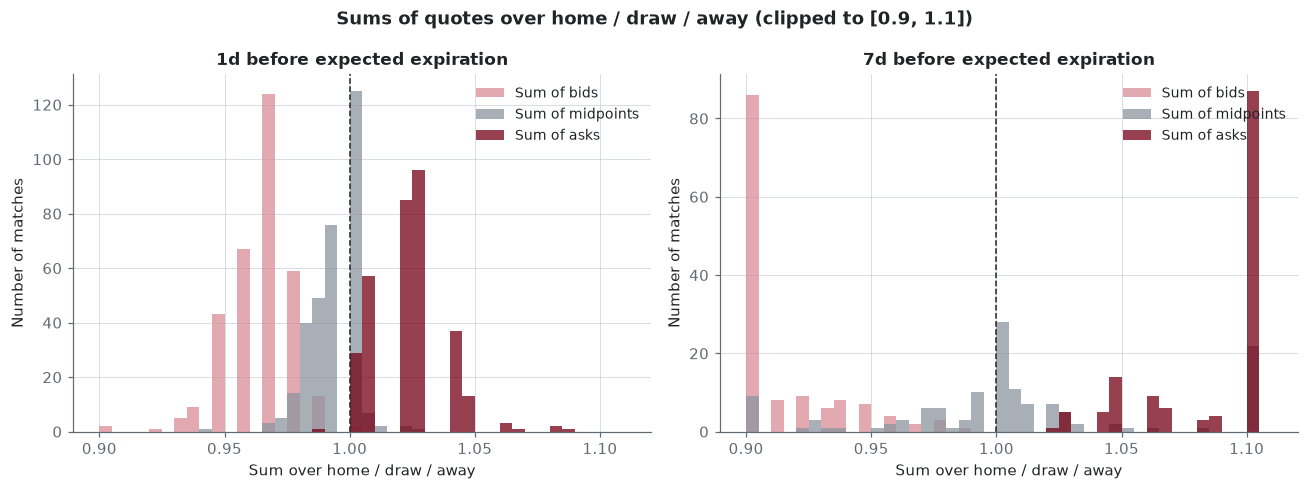

Rows outside the plotted range: {'1d': 2, '7d': 88}


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, h in zip(axes, ["1d", "7d"]):
    sub = df[df["horizon"] == h]
    bins = np.arange(0.90, 1.11, 0.005)
    ax.hist(sub["sum_bid"].clip(0.9, 1.1), bins=bins, alpha=.75, color=MIT["light_red"], label="Sum of bids")
    ax.hist(sub["sum_midpoints"].clip(0.9, 1.1), bins=bins, alpha=.75, color=MIT["silver"], label="Sum of midpoints")
    ax.hist(sub["sum_ask"].clip(0.9, 1.1), bins=bins, alpha=.75, color=MIT["mit_red"], label="Sum of asks")
    ax.axvline(1, color=MIT["black"], ls="--", lw=1)
    ax.set_title(f"{h} before expected expiration")
    ax.set_xlabel("Sum over home / draw / away")
    ax.set_ylabel("Number of matches")
    ax.legend()
fig.suptitle("Sums of quotes over home / draw / away (clipped to [0.9, 1.1])", fontweight="bold")
plt.tight_layout()
save_fig("sum_of_quotes")
plt.show()

print("Rows outside the plotted range:",
      ((df["sum_bid"] < .9) | (df["sum_ask"] > 1.1)).groupby(df["horizon"]).sum().to_dict())

3. Are prices calibrated Pr?

A forecast is calibrated if, among all contracts priced near $p$, a fraction $p$ resolve YES. 3 tests: reliability
table/diagram, proper scoring rules vs a naive benchmark, and a calibration regression for the favorite–longshot bias.

Key stat point: the 3 legs of a match aren't independent (exactly 1 pays and prices sum to ≈ 1)
-> every CI comes from a cluster bootstrap that resamples whole matches, never individual legs.

In [19]:
# drop degenerate midpoints that make logit/log-loss undefined (+ report them)
valid_probs = np.logical_and.reduce([df[f"{leg}_midpoint"].between(0,1,inclusive="neither") for leg in LEGS])
print("Excluded degenerate midpoint match-horizons:", int((~valid_probs).sum()))
df = df.loc[valid_probs].reset_index(drop=True)

# 1 row per (match, horizon, leg) = 1 Pr forecast
long = pd.concat([
    pd.DataFrame({
        "event_ticker": df["event_ticker"],
        "horizon": df["horizon"],
        "leg": leg,
        "p": df[f"{leg}_midpoint"],  # raw midpoint price
        "p_norm": df[f"{leg}_midpoint"] / df["sum_midpoints"],  # rescaled so the 3 legs sum to 1
        "max_spread": df["max_spread"],
        "y": df[f"{leg}_won"],
    })
    for leg in LEGS
], ignore_index=True)

print(long.shape)
print(long.head(6).to_string(index=False))

Excluded degenerate midpoint match-horizons: 0
(1377, 7)
                  event_ticker horizon  leg     p   p_norm  max_spread  y
KXEREDIVISIEGAME-25DEC05EXCGRO      1d home 0.280 0.282828        0.04  0
KXEREDIVISIEGAME-25DEC05EXCGRO      7d home 0.225 0.335821        0.41  0
KXEREDIVISIEGAME-25DEC06FEYZWO      1d home 0.840 0.840000        0.02  1
KXEREDIVISIEGAME-25DEC06FEYZWO      7d home 0.490 0.720588        0.72  1
KXEREDIVISIEGAME-25DEC06FORAJA      1d home 0.215 0.216080        0.04  0
KXEREDIVISIEGAME-25DEC06FORAJA      7d home 0.155 0.236641        0.59  0


Assumption checks on the forecast table

In [20]:
g = long.groupby(["event_ticker", "horizon"])
assert (g.size() == 3).all(), "each match-horizon must have 3 legs"
assert (g["y"].sum() == 1).all(), "exactly one leg pays"
assert np.allclose(g["p_norm"].sum(), 1), "normalized probabilities must sum to 1"
assert long["p"].between(0, 1, inclusive="neither").all(), "logit needs 0 < p < 1"
print("3 legs, one winner, normalized sums = 1, 0 < p < 1: OK")

# only matches seen at BOTH horizons -> 1d vs 7d compares the same games
n_h = long.groupby("event_ticker")["horizon"].nunique()
paired = n_h[n_h == 2].index
print(f"matches with both horizons: {len(paired)} of {len(n_h)} (dropping {len(n_h) - len(paired)})")
long = long[long["event_ticker"].isin(paired)].reset_index(drop=True)
print(long.groupby("horizon").size().rename("forecasts per horizon"))

3 legs, one winner, normalized sums = 1, 0 < p < 1: OK
matches with both horizons: 134 of 325 (dropping 191)
horizon
1d    402
7d    402
Name: forecasts per horizon, dtype: int64


In [21]:
# sanity test on the Brier score (MSE over legs)
# equal cluster sizes (3 legs) -> analytical clustered SE = SE of the per-match means
test = long[long["horizon"] == "1d"].reset_index(drop=True)
sq = (test["p"] - test["y"]) ** 2
boot = cluster_bootstrap(test, lambda d: ((d["p"] - d["y"]) ** 2).mean())
match_means = sq.groupby(test["event_ticker"]).mean()
print(f"cluster bootstrap SE   {boot.std():.5f}")
print(f"analytical cluster SE  {match_means.std(ddof=1) / np.sqrt(len(match_means)):.5f}")
print(f"naive iid SE (wrong)   {sq.std(ddof=1) / np.sqrt(len(sq)):.5f}")

# nb: DON'T use mean(y - p) as a test stat across all legs: within a match the
# 3 y's sum to 1 and the 3 p's sum to ~1 -> ~0 by construction

cluster bootstrap SE   0.01162
analytical cluster SE  0.01132
naive iid SE (wrong)   0.01083


3a. Reliability table + diagram

10 equal-width Pr bins. For each bin: avg price, realized YES freq, count, and a 95% cluster-bootstrap CI for the freq.
Bins with < 30 forecasts are flagged -> freqs too noisy to interpret
(and a bin where every outcome is 0 gets a degenerate bootstrap CI of [0, 0]).
With ~18 bin-level comparisons, ≈ 1 "price outside CI" is expected by chance at 5%.

In [22]:
tables = {}
for h in ["1d", "7d"]:
    d = long[long["horizon"] == h].reset_index(drop=True)
    tab = reliability(d).dropna(subset=["avg_price"])  # keep non-empty bins only
    boot = cluster_bootstrap(d, lambda s: reliability(s)["freq_yes"].reindex(tab.index).values)
    tab["ci_low"] = np.nanpercentile(boot, 2.5, axis=0)
    tab["ci_high"] = np.nanpercentile(boot, 97.5, axis=0)
    tab["price_in_ci"] = tab["avg_price"].between(tab["ci_low"], tab["ci_high"])
    tab["small_bin"] = tab["n"] < 30
    tables[h] = tab
    print(f"\n{h} before expected expiration")
    print(tables[h].round(3).to_string())


1d before expected expiration
                 n  avg_price  freq_yes  ci_low  ci_high  price_in_ci  small_bin
p                                                                               
(-0.001, 0.1]   20      0.070     0.050   0.000    0.158         True       True
(0.1, 0.2]      83      0.157     0.217   0.141    0.297         True      False
(0.2, 0.3]     124      0.240     0.266   0.198    0.339         True      False
(0.3, 0.4]      59      0.352     0.424   0.333    0.520         True      False
(0.4, 0.5]      36      0.445     0.306   0.152    0.455         True      False
(0.5, 0.6]      31      0.561     0.581   0.400    0.750         True      False
(0.6, 0.7]      24      0.651     0.500   0.292    0.696         True       True
(0.7, 0.8]      17      0.749     0.647   0.400    0.875         True       True
(0.8, 0.9]       7      0.848     0.571   0.200    1.000         True       True
(0.9, 1.0]       1      0.905     1.000   1.000    1.000        False       Tr


7d before expected expiration
                 n  avg_price  freq_yes  ci_low  ci_high  price_in_ci  small_bin
p                                                                               
(-0.001, 0.1]   11      0.069     0.000   0.000    0.000        False       True
(0.1, 0.2]      90      0.162     0.233   0.156    0.316         True      False
(0.2, 0.3]     111      0.246     0.270   0.200    0.344         True      False
(0.3, 0.4]      41      0.354     0.366   0.255    0.477         True      False
(0.4, 0.5]      79      0.445     0.367   0.302    0.443        False      False
(0.5, 0.6]      26      0.558     0.500   0.300    0.696         True       True
(0.6, 0.7]      24      0.650     0.542   0.333    0.760         True       True
(0.7, 0.8]      16      0.733     0.625   0.375    0.857         True       True
(0.8, 0.9]       3      0.843     0.667   0.000    1.000         True       True
(0.9, 1.0]       1      0.910     1.000   1.000    1.000        False       Tr

In [23]:
pd.concat([t.assign(horizon=h) for h,t in tables.items()]).to_csv(RESULT_DIR / "reliability.csv", index=False)

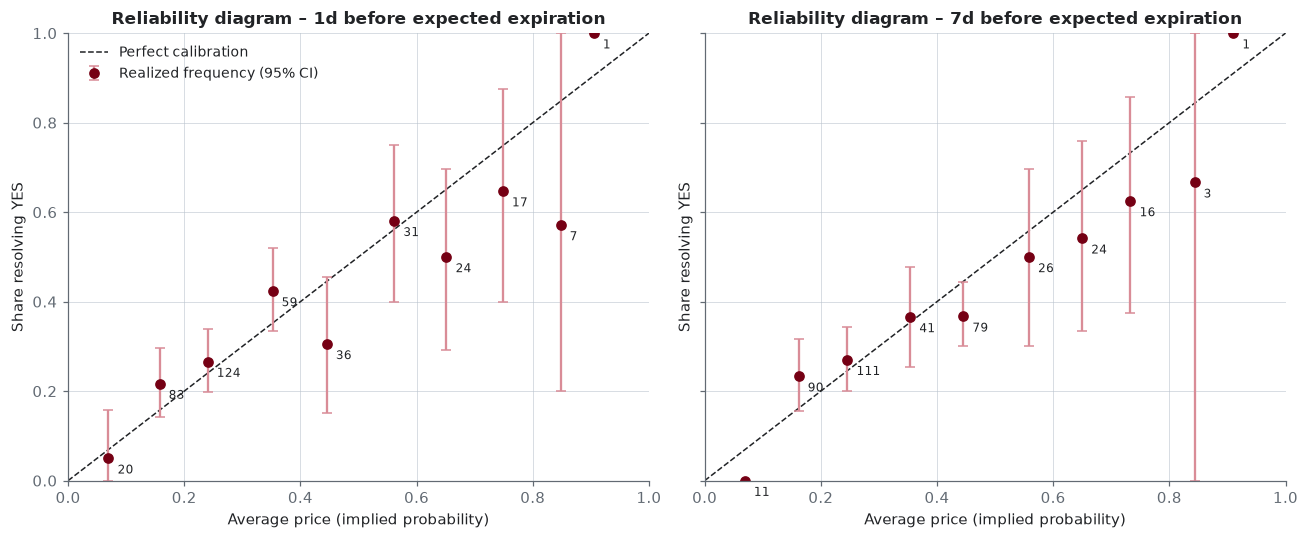

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, h in zip(axes, ["1d", "7d"]):
    t = tables[h]
    ax.plot([0, 1], [0, 1], "--", color=MIT["black"], lw=1, label="Perfect calibration")
    ax.errorbar(t["avg_price"], t["freq_yes"],
                yerr=[t["freq_yes"] - t["ci_low"], t["ci_high"] - t["freq_yes"]],
                fmt="o", capsize=3, color=MIT["mit_red"], ecolor=MIT["light_red"], label="Realized frequency (95% CI)")
    for _, r in t.iterrows():
        ax.annotate(int(r["n"]), (r["avg_price"], r["freq_yes"]), xytext=(6, -10), textcoords="offset points", fontsize=8)
    ax.set_title(f"Reliability diagram – {h} before expected expiration")
    ax.set_xlabel("Average price (implied probability)")
    ax.set_ylabel("Share resolving YES")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].legend(loc="upper left")
plt.tight_layout()
save_fig("reliability_diagram")
plt.show()

3b. Scoring rules vs a naive benchmark

- Brier score $\frac1N\sum (p-y)^2$ and log loss $-\frac1N\sum [y\ln p + (1-y)\ln(1-p)]$: lower = better.
- Benchmark: always predict the sample base rate of each leg (home / draw / away). Uses realized outcomes -> generous to the benchmark.
- Murphy decomposition w/ same 10 bins: Brier ≈ Reliability − Resolution + Uncertainty.
  Reliability = miscalibration (want ≈ 0); Resolution = how well prices separate likely from unlikely outcomes (want large).

In [25]:
rows = []
for h in ["1d", "7d"]:
    d = long[long["horizon"] == h]
    base = d.groupby("leg")["y"].transform("mean")
    for name, p in [("market midpoint", d["p"]), ("market normalized", d["p_norm"]), ("base-rate benchmark", base)]:
        rows.append({"horizon": h, "forecast": name, "brier": brier(p, d["y"]), "log_loss": log_loss(p, d["y"])})
    rel, res, unc = murphy(d)
    bs = brier(d["p"], d["y"])
    rows[-3].update(reliability=rel, resolution=res, uncertainty=unc, decomp_residual=bs - (rel - res + unc))

scores = pd.DataFrame(rows)
bench = scores[scores["forecast"] == "base-rate benchmark"].set_index("horizon")["brier"]
scores["brier_skill_vs_benchmark"] = 1 - scores["brier"] / scores["horizon"].map(bench)
print(scores.round(4).to_string(index=False))

horizon            forecast  brier  log_loss  reliability  resolution  uncertainty  decomp_residual  brier_skill_vs_benchmark
     1d     market midpoint 0.2064    0.6015       0.0066      0.0221       0.2222          -0.0003                    0.0657
     1d   market normalized 0.2065    0.6017          NaN         NaN          NaN              NaN                    0.0656
     1d base-rate benchmark 0.2209    0.6336          NaN         NaN          NaN              NaN                    0.0000
     7d     market midpoint 0.2109    0.6099       0.0043      0.0164       0.2222           0.0008                    0.0453
     7d   market normalized 0.2080    0.6037          NaN         NaN          NaN              NaN                    0.0587
     7d base-rate benchmark 0.2209    0.6336          NaN         NaN          NaN              NaN                    0.0000


In [26]:
scores.to_csv(RESULT_DIR / "forecast_scores.csv", index=False)

3c. Calibration regression (favorite–longshot bias)

Fit $\Pr(y=1) = \Lambda\big(a + b\,\text{logit}(p)\big)$. Perfect calibration = $a=0,\ b=1$.

- $b > 1$: true Pr more extreme than prices → longshots overpriced, favorites underpriced (favorite–longshot bias).
- $b < 1$: prices too extreme → market is overconfident.

Fit = short Newton–Raphson routine (checked vs scipy below); SEs from the match-level cluster bootstrap.
With `statsmodels` same thing: `sm.Logit(y, X).fit(cov_type="cluster", cov_kwds={"groups": match_id})`.

In [27]:
# test 1: FOCs of the MLE, sum(y - mu) = 0 and sum((y - mu) * x) = 0
d = long[long["horizon"] == "1d"]
x, y = logit(d["p"]).values, d["y"].values
ours = fit_logit(x, y)
mu = 1 / (1 + np.exp(-(ours[0] + ours[1] * x)))
print("score equations:", np.round([np.sum(y - mu), np.sum((y - mu) * x)], 8))

# test 2: same answer as a generic optimizer on the neg log-likelihood
nll = lambda b: -np.sum(y * (b[0] + b[1] * x) - np.log1p(np.exp(b[0] + b[1] * x)))
ref = minimize(nll, x0=[0.0, 1.0], method="BFGS").x
print("Newton:", ours.round(5), "| scipy BFGS:", ref.round(5))
assert np.allclose(ours, ref, atol=1e-3)

score equations: [-0.  0.]
Newton: [-0.20561  0.67442] | scipy BFGS: [-0.20561  0.67442]


In [28]:
reg = []
for h in ["1d", "7d"]:
    d = long[long["horizon"] == h].reset_index(drop=True)
    a, b = fit_logit(logit(d["p"]).values, d["y"].values)
    boot = cluster_bootstrap(d, lambda s: fit_logit(logit(s["p"]).values, s["y"].values))
    se_a, se_b = boot.std(axis=0)
    t_b = (b - 1) / se_b
    reg.append({"horizon": h, "a": a, "se_a": se_a, "b": b, "se_b": se_b,
                "b_95CI": f"[{np.percentile(boot[:, 1], 2.5):.2f}, {np.percentile(boot[:, 1], 97.5):.2f}]",
                "t(b=1)": t_b, "p(b=1)": 2 * norm.sf(abs(t_b)),
                "corr(a_hat, b_hat)": np.corrcoef(boot.T)[0, 1]})
print(pd.DataFrame(reg).round(3).to_string(index=False))

horizon      a  se_a     b  se_b       b_95CI  t(b=1)  p(b=1)  corr(a_hat, b_hat)
     1d -0.206 0.108 0.674 0.163 [0.39, 1.01]  -1.992   0.046                1.00
     7d -0.249 0.102 0.659 0.164 [0.37, 1.00]  -2.078   0.038                0.99


In [29]:
pd.DataFrame(reg).to_csv(RESULT_DIR / "calibration_regression.csv", index=False)

3d. Bias by leg (is the draw mispriced?)

For each leg, avg price vs realized freq. Within 1 leg each match gives a single forecast
-> bootstrap here is just ordinary resampling of matches.

In [30]:
leg_rows = []
for h in ["1d", "7d"]:
    for leg in LEGS:
        d = long[(long["horizon"] == h) & (long["leg"] == leg)].reset_index(drop=True)
        gap = (d["y"] - d["p"]).mean()
        boot = cluster_bootstrap(d, lambda s: (s["y"] - s["p"]).mean())
        leg_rows.append({"horizon": h, "leg": leg, "n": len(d), "avg_price": d["p"].mean(),
                         "freq_yes": d["y"].mean(), "gap (freq - price)": gap,
                         "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5)})
legs = pd.DataFrame(leg_rows)
legs["significant_5%"] = (legs["ci_low"] > 0) | (legs["ci_high"] < 0)
print(legs.round(3).to_string(index=False))

horizon  leg   n  avg_price  freq_yes  gap (freq - price)  ci_low  ci_high  significant_5%
     1d home 134      0.447     0.366              -0.081  -0.159   -0.002            True
     1d draw 134      0.210     0.284               0.074  -0.002    0.152           False
     1d away 134      0.341     0.351               0.010  -0.062    0.081           False
     7d home 134      0.434     0.366              -0.069  -0.148    0.012           False
     7d draw 134      0.240     0.284               0.044  -0.033    0.122           False
     7d away 134      0.352     0.351              -0.001  -0.075    0.070           False


In [31]:
legs.to_csv(RESULT_DIR / "outcome_gaps.csv", index=False)

3e. Do prices get better closer to kickoff?

Per-match Brier = sum over the 3 legs of $(p-y)^2$. Same matches at both horizons -> test the paired diff.

In [32]:
long["sq_err"] = (long["p"] - long["y"]) ** 2
per_match = long.pivot_table(index="event_ticker", columns="horizon", values="sq_err", aggfunc="sum")
per_match["diff_7d_minus_1d"] = per_match["7d"] - per_match["1d"]

rng = np.random.default_rng(SEED)
diffs = per_match["diff_7d_minus_1d"].values
boot = np.array([rng.choice(diffs, len(diffs)).mean() for _ in range(B)])

print(f"Mean per-match Brier: 7d {per_match['7d'].mean():.4f} | 1d {per_match['1d'].mean():.4f}")
print(f"Improvement 7d -> 1d: {diffs.mean():.4f}  95% CI [{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]")
print(f"Relative improvement: {100 * diffs.mean() / per_match['7d'].mean():.1f}%")
print(f"Matches where 1d beat 7d: {(diffs > 0).mean():.1%}")

Mean per-match Brier: 7d 0.6328 | 1d 0.6193
Improvement 7d -> 1d: 0.0135  95% CI [-0.0122, 0.0388]
Relative improvement: 2.1%
Matches where 1d beat 7d: 57.5%


3f. Sensitivity: drop illiquid books

Midpoints of very wide books (some leg w/ spread > 10¢, almost always at 7d) aren't informative prices
-> re-run the headline numbers w/o them.

In [33]:
rows = []
for label, mask in [("all rows", long["max_spread"] >= 0), ("max spread <= 10c", long["max_spread"] <= 0.10)]:
    for h in ["1d", "7d"]:
        d = long[mask & (long["horizon"] == h)]
        a, b = fit_logit(logit(d["p"]).values, d["y"].values)
        rows.append({"sample": label, "horizon": h, "forecasts": len(d),
                     "brier": brier(d["p"], d["y"]), "log_loss": log_loss(d["p"], d["y"]),
                     "reliability": murphy(d)[0], "a": a, "b": b})
print(pd.DataFrame(rows).round(4).to_string(index=False))

           sample horizon  forecasts  brier  log_loss  reliability       a      b
         all rows      1d        402 0.2064    0.6015       0.0066 -0.2056 0.6744
         all rows      7d        402 0.2109    0.6099       0.0043 -0.2486 0.6589
max spread <= 10c      1d        402 0.2064    0.6015       0.0066 -0.2056 0.6744
max spread <= 10c      7d        210 0.1919    0.5663       0.0026 -0.0900 0.8532


4. When do prices deviate from theory, and why?

Topic asks whether deviations are linked to time to resolution, bid-ask spread, trading volume, or event category,
and whether apparent arbs persist. 2 kinds of deviation:

1. No-arb deviation – how far the 3 midpoints sum from \$1 (section 2).
2. Pr deviation – whether calibration (section 3) is worse in illiquid markets.

Then we leave the 2 fixed horizons and scan every hourly snapshot b4 kickoff.

4a. 1 row per match-horizon: deviation + candidate drivers

| Variable | Definition | Topic's category |
|---|---|---|
| `abs_dev_c` | $\lvert\sum \text{mid} - 1\rvert$ in cents | deviation |
| `max_spread_c` | widest of the three bid-ask spreads, cents | bid-ask spread |
| `log_volume`, `log_oi` | log(1 + total contracts traded in the candle / open interest) | volume / liquidity |
| `quote_age_h` | oldest of the three quotes, hours | staleness |
| `is_7d` | 1 for the 7-day horizon | time to resolution |
| `fav_prob` | largest normalized probability (how one-sided the match is) | event category |

In [34]:
X = pd.DataFrame({"event_ticker": df["event_ticker"], "horizon": df["horizon"]})
X["dev_c"] = 100 * (df["sum_midpoints"] - 1)
X["abs_dev_c"] = X["dev_c"].abs()
X["max_spread_c"] = (100 * df["max_spread"]).round(4)
X["log_volume"] = np.log1p(df[[f"{l}_volume" for l in LEGS]].sum(axis=1))
X["log_oi"] = np.log1p(df[[f"{l}_open_interest" for l in LEGS]].sum(axis=1))
X["quote_age_h"] = df[[f"{l}_quote_age_minutes" for l in LEGS]].max(axis=1) / 60
X["is_7d"] = (df["horizon"] == "7d").astype(int)
X["fav_prob"] = df[[f"{l}_midpoint" for l in LEGS]].max(axis=1) / df["sum_midpoints"]


DRIVERS = ["max_spread_c", "log_volume", "log_oi", "quote_age_h", "is_7d", "fav_prob"]

# assumption checks
assert X[DRIVERS + ["abs_dev_c"]].notna().all().all(), "missing values"
print("Share of match-horizons with zero volume in the candle:", round((X["log_volume"] == 0).mean(), 3))

print("\nDistribution of the deviation (cents):")
print(X.groupby("horizon")["abs_dev_c"].describe(percentiles=[.5, .9, .99]).round(2))

# collinearity: VIF_j = 1 / (1 - R^2 of driver j on the other drivers)
def vif(D):
    out = {}
    for c in D.columns:
        Z = np.column_stack([np.ones(len(D)), D.drop(columns=c).values])
        resid = D[c].values - Z @ np.linalg.lstsq(Z, D[c].values, rcond=None)[0]
        out[c] = D[c].values.var() / resid.var()
    return pd.Series(out)

print("\nCorrelations above 0.6:", [(a, b, round(X[a].corr(X[b]), 2)) for i, a in enumerate(DRIVERS)
                                   for b in DRIVERS[i + 1:] if abs(X[a].corr(X[b])) > 0.6])
print("VIF (rule of thumb: worry above 5):"); print(vif(X[DRIVERS]).round(2).to_string())

Share of match-horizons with zero volume in the candle: 0.815

Distribution of the deviation (cents):
         count  mean    std  min  50%   90%   99%   max
horizon                                                
1d       325.0  0.73   0.72  0.0  0.5   1.5   3.0   5.5
7d       134.0  8.13  12.44  0.0  2.0  32.7  45.0  45.5

Correlations above 0.6: [('log_oi', 'is_7d', np.float64(-0.6))]
VIF (rule of thumb: worry above 5):
max_spread_c    1.56
log_volume      1.28
log_oi          2.13
quote_age_h     1.02
is_7d           2.09
fav_prob        1.27


In [35]:
X.to_csv(RESULT_DIR / "liquidity_drivers.csv", index=False)

4b. Simple tables first

B4 any regression: avg + median deviation within buckets of each driver.

In [36]:
def by_bucket(col, buckets=None, labels=None):
    key = pd.cut(X[col], buckets, labels=labels) if buckets is not None else X[col]
    return X.groupby(key, observed=True)["abs_dev_c"].agg(n="size", mean="mean", median="median").round(2)

print("By widest spread (cents)");   print(by_bucket("max_spread_c", [0, 2, 5, 10, 100]))
print("\nBy volume");               print(X.groupby(pd.qcut(X["log_volume"].rank(method="first"), 3, labels=["low", "mid", "high"]))["abs_dev_c"].agg(n="size", mean="mean", median="median").round(2))
print("\nBy horizon");              print(by_bucket("horizon"))

print("\nBy how one-sided the match is"); print(by_bucket("fav_prob", [0, .45, .55, .65, 1]))

By widest spread (cents)
                n   mean  median
max_spread_c                    
(0, 2]        222   0.66    0.50
(2, 5]        132   0.93    0.50
(5, 10]        41   1.38    1.00
(10, 100]      64  15.66    8.25

By volume
              n  mean  median
log_volume                   
low         153  5.15     0.5
mid         153  1.20     1.0
high        153  2.34     0.5

By horizon
           n  mean  median
horizon                   
1d       325  0.73     0.5
7d       134  8.13     2.0

By how one-sided the match is
                n  mean  median
fav_prob                       
(0.0, 0.45]   140  5.48     0.5
(0.45, 0.55]   98  2.22     1.0
(0.55, 0.65]  104  1.55     0.5
(0.65, 1.0]   117  1.56     1.0


4c. Regression w/ match-clustered SEs

$$\lvert\textstyle\sum \text{mid} - 1\rvert_{i,h} = \alpha + \beta^\top \text{drivers}_{i,h} + \varepsilon_{i,h}$$

Each match shows up twice (1d + 7d) -> errors clustered by match. OLS + cluster-robust (CR1) sandwich are a few lines of
numpy, both checked below. With `statsmodels`: `sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": match_id})`.

Run on all rows and again w/o illiquid books (spread > 10¢), so a handful of extreme rows can't drive the result.
Volume, OI and the 7d dummy are correlated (VIFs printed in 4a): if < 5 the model is estimable,
but their separate coeffs are imprecise. Time to resolution is studied more cleanly w/ the hourly data in 4e.

In [37]:
# test 1: coeffs = numpy's least squares
y = X["abs_dev_c"].values
M = X[DRIVERS].values
beta, se, r2 = ols_cluster(y, M, X["event_ticker"])
ref = np.linalg.lstsq(np.column_stack([np.ones(len(M)), M]), y, rcond=None)[0]
assert np.allclose(beta, ref)
print("OLS coefficients match np.linalg.lstsq: OK")

# test 2: cluster SEs ≈ cluster bootstrap
rng = np.random.default_rng(SEED)
rows_by_match = list(X.groupby("event_ticker").indices.values())
boot = []
for _ in range(B):
    r = np.concatenate([rows_by_match[i] for i in rng.integers(0, len(rows_by_match), len(rows_by_match))])
    boot.append(np.linalg.lstsq(np.column_stack([np.ones(len(r)), M[r]]), y[r], rcond=None)[0])
print(pd.DataFrame({"CR1 SE": se, "bootstrap SE": np.array(boot).std(axis=0)}, index=["const"] + DRIVERS).round(3))

OLS coefficients match np.linalg.lstsq: OK
              CR1 SE  bootstrap SE
const          0.407         0.402
max_spread_c   0.024         0.024
log_volume     0.032         0.033
log_oi         0.027         0.027
quote_age_h    0.164         0.165
is_7d          0.299         0.295
fav_prob       0.736         0.727


In [38]:
def reg_table(data):
    b, s, r2 = ols_cluster(data["abs_dev_c"].values, data[DRIVERS].values, data["event_ticker"])
    t = pd.DataFrame({"coef": b, "se": s, "t": b / s}, index=["const"] + DRIVERS)
    return t, r2, len(data)

for label, data in [("all rows", X), ("spread <= 10c", X[X["max_spread_c"] <= 10])]:
    t, r2, n = reg_table(data)
    print(f"\n=== {label}: n = {n}, R^2 = {r2:.3f} ===")
    print(t.round(3).to_string())


=== all rows: n = 459, R^2 = 0.881 ===
               coef     se       t
const        -0.856  0.407  -2.102
max_spread_c  0.461  0.024  19.200
log_volume    0.013  0.032   0.418
log_oi        0.079  0.027   2.932
quote_age_h  -0.171  0.164  -1.042
is_7d        -1.226  0.299  -4.107
fav_prob      0.577  0.736   0.784

=== spread <= 10c: n = 395, R^2 = 0.093 ===
               coef     se      t
const         0.068  0.245  0.278
max_spread_c  0.075  0.044  1.694
log_volume    0.008  0.027  0.287
log_oi        0.036  0.019  1.926
quote_age_h  -0.025  0.045 -0.557
is_7d         0.335  0.237  1.410
fav_prob      0.647  0.350  1.846


In [39]:
reg_table(X)[0].to_csv(RESULT_DIR / "liquidity_regression.csv")

4d. Are prices worse Pr when the market is illiquid?

Split forecasts by liquidity of their match-horizon and redo the step-3 diagnostics in each group:
Brier, reliability term of the Murphy decomposition (pure miscalibration), and calibration slope $b$.
Groups defined at match level -> all 3 legs of a match stay together and the clustering logic of step 3 still holds.

In [40]:
f = long.merge(X[["event_ticker", "horizon", "log_volume", "max_spread_c"]], on=["event_ticker", "horizon"], how="left")
assert f["log_volume"].notna().all() and len(f) == len(long)
f["liquidity"] = np.select([f["max_spread_c"] <= 2, f["max_spread_c"] <= 5], ["tight (<=2c)", "medium (2-5c)"], "wide (>5c)")
f["traded"] = np.where(f["log_volume"] > 0, "traded in candle", "no trades in candle")

rows = []
for col in ["liquidity", "traded"]:
    for grp, d in f.groupby(col):
        d = d.reset_index(drop=True)
        b_hat = fit_logit(logit(d["p"]).values, d["y"].values)[1]
        idx = list(d.groupby("event_ticker").indices.values())
        rng = np.random.default_rng(SEED)
        bs = [fit_logit(logit(d["p"].values[r]), d["y"].values[r])[1]
              for r in (np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))]) for _ in range(B))]
        rows.append({"split": col, "group": grp, "matches": d["event_ticker"].nunique(), "forecasts": len(d),
                     "brier": np.mean((d["p"] - d["y"]) ** 2), "reliability": reliability_term(d["p"], d["y"], BINS),
                     "slope_b": b_hat, "b_ci_low": np.percentile(bs, 2.5), "b_ci_high": np.percentile(bs, 97.5)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

    split               group  matches  forecasts  brier  reliability  slope_b  b_ci_low  b_ci_high
liquidity       medium (2-5c)       43        135 0.2024       0.0097   0.7888    0.2907     1.4495
liquidity        tight (<=2c)      119        363 0.2014       0.0067   0.7148    0.4431     1.0535
liquidity          wide (>5c)      102        306 0.2202       0.0079   0.5253    0.1762     0.9094
   traded no trades in candle      132        672 0.2073       0.0042   0.6975    0.3948     1.0721
   traded    traded in candle       42        132 0.2158       0.0226   0.5432    0.0690     1.1603


4e. Every hour b4 kickoff: time to resolution + persistence of arb

The 2 fixed horizons are snapshots; hourly candles let us follow each match from listing to kickoff.

Cleaning rules (each checked below):
- keep an hour only if all 3 legs have a candle at that timestamp;
- keep only pre-match hours: b4 min(expected expiration, settlement) − 3h. Expected expiration ≈ kickoff + 3h (step 1),
  and taking the min also handles games moved earlier or settled late;
- hours to kickoff = expected expiration − 3h − timestamp.

Hourly candles were downloaded for ≈ the last 8 days b4 each match -> this section covers ≈ 0–8 days to kickoff.

In [41]:
hc = candles.copy()
mk = markets[markets["status"] == "finalized"].drop_duplicates("event_ticker").set_index("event_ticker")

hc["timestamp"] = pd.to_datetime(hc["timestamp"], utc=True)
exp_time = pd.to_datetime(mk["expected_expiration_time"], utc=True)
settle = pd.to_datetime(mk["settlement_ts"], utc=True)
cutoff = (np.minimum(exp_time, settle) - pd.Timedelta(hours=3))

# assumption checks on the raw hourly file
assert (hc["timestamp"].dt.minute == 0).all(), "candles should sit on the hour"
assert (hc["yes_bid"] <= hc["yes_ask"]).all(), "bid above ask"
print("Rows:", len(hc), "| empty-book quotes (bid = 0 or ask = 1):", round(((hc.yes_bid == 0) | (hc.yes_ask == 1)).mean(), 4))

pre = hc[hc["timestamp"] < hc["event_ticker"].map(cutoff)].copy()
print("Pre-match rows:", len(pre), f"({len(pre) / len(hc):.1%} of all)")

# per-leg fees, then aggregate the 3 legs of each match-hour
pre["fee_buy"] = np.ceil(100 * FEE_RATE * pre["yes_ask"] * (1 - pre["yes_ask"])) / 100
no_price = 1 - pre["yes_bid"]
pre["fee_sell"] = np.ceil(100 * FEE_RATE * no_price * (1 - no_price)) / 100
# P(1-P) terms -> unrounded fee = FEE_RATE * q, so we can solve for a break-even fee rate
pre["q_buy"] = pre["yes_ask"] * (1 - pre["yes_ask"])
pre["q_sell"] = no_price * (1 - no_price)

H = pre.groupby(["event_ticker", "timestamp"]).agg(
    legs=("ticker", "nunique"), sum_bid=("yes_bid", "sum"), sum_ask=("yes_ask", "sum"),
    fee_buy=("fee_buy", "sum"), fee_sell=("fee_sell", "sum"), q_buy=("q_buy", "sum"), q_sell=("q_sell", "sum"),
    volume=("volume", "sum")).reset_index()
print("Match-hours by number of legs quoted:", H["legs"].value_counts().to_dict())
H = H[H["legs"] == 3].copy()

for c in ["sum_bid", "sum_ask", "fee_buy", "fee_sell"]:
    H[c] = H[c].round(4)  # cent prices: kill float noise b4 comparing w/ 1
H["sum_mid"] = (H["sum_bid"] + H["sum_ask"]) / 2
H["hours_to_ko"] = (H["event_ticker"].map(exp_time) - pd.Timedelta(hours=3) - H["timestamp"]).dt.total_seconds() / 3600
tau = (H["event_ticker"].map(settle) - H["timestamp"]).dt.total_seconds() / (365 * 24 * 3600)
disc = np.exp(-R * tau)
H["profit_buy_nofee"] = (disc - H["sum_ask"]).round(4)
H["profit_sell_nofee"] = (2 * disc - (3 - H["sum_bid"])).round(4)
H["profit_buy"] = (H["profit_buy_nofee"] - H["fee_buy"]).round(4)
H["profit_sell"] = (H["profit_sell_nofee"] - H["fee_sell"]).round(4)

assert (H["hours_to_ko"] > 0).all()
print(f"Usable match-hours: {len(H)} across {H['event_ticker'].nunique()} matches; "
      f"median {H.groupby('event_ticker').size().median():.0f} hours per match")

Rows: 102509 | empty-book quotes (bid = 0 or ask = 1): 0.0136
Pre-match rows: 98695 (96.3% of all)
Match-hours by number of legs quoted: {3: 28077, 2: 5424, 1: 3616}
Usable match-hours: 28077 across 327 matches; median 79 hours per match


In [42]:
H.to_csv(RESULT_DIR / "hourly_arbitrage.csv", index=False)

Coverage: up to 7.8 days before kickoff
            match_hours  median_band_c  mean_abs_dev_c  share_dev_over_2c  median_volume
days_to_ko                                                                              
[0, 1)             6733            4.0           0.663              0.053           4.08
[1, 2)             5495            6.0           0.889              0.129           0.00
[2, 3)             4956            8.0           1.428              0.239           0.00
[3, 5)             5857           10.0           2.260              0.289           0.00
[5, 7)             4091           15.0           4.297              0.383           0.00
[7, 8)              945           88.0          18.904              0.786           0.00


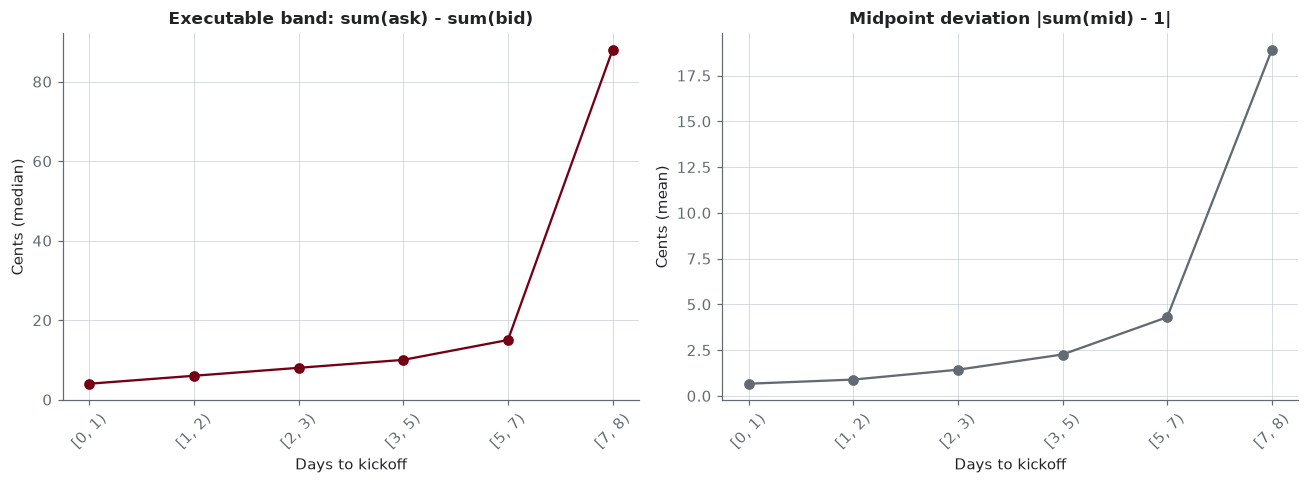

In [43]:
print("Coverage: up to", round(H["hours_to_ko"].max() / 24, 1), "days before kickoff")
H["days_to_ko"] = pd.cut(H["hours_to_ko"] / 24, [0, 1, 2, 3, 5, 7, 8], right=False)
T = H.groupby("days_to_ko", observed=True).agg(
    match_hours=("sum_mid", "size"),
    median_band_c=("sum_ask", lambda s: 100 * (s - H.loc[s.index, "sum_bid"]).median()),
    mean_abs_dev_c=("sum_mid", lambda s: 100 * (s - 1).abs().mean()),
    share_dev_over_2c=("sum_mid", lambda s: ((s - 1).abs() > 0.02).mean()),
    median_volume=("volume", "median"))
print(T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = [str(i) for i in T.index]
axes[0].plot(x, T["median_band_c"], "o-", color=MIT["mit_red"]); axes[0].set_title("Executable band: sum(ask) - sum(bid)")
axes[0].set_ylabel("Cents (median)")
axes[1].plot(x, T["mean_abs_dev_c"], "o-", color=MIT["dark_gray"]); axes[1].set_title("Midpoint deviation |sum(mid) - 1|")
axes[1].set_ylabel("Cents (mean)")
for ax in axes:
    ax.set_xlabel("Days to kickoff"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save_fig("band_by_time_to_kickoff")
plt.show()

In [44]:
print("Share of pre-match hours with an executable arbitrage")
for label, cb, cs in [("zero fees", "profit_buy_nofee", "profit_sell_nofee"), ("with fees", "profit_buy", "profit_sell")]:
    hit = (H[cb] > 0) | (H[cs] > 0)
    print(f"  {label:9s}: {hit.sum():5d} of {len(H)} hours ({hit.mean():.2%}) in {H.loc[hit, 'event_ticker'].nunique()} matches; "
          f"best profit {max(H[cb].max(), H[cs].max()):+.4f}")

# fee sensitivity: fee rate is an unverified assumption -> find the rate at which arb would appear
unrounded = np.maximum(H["profit_buy_nofee"] - FEE_RATE * H["q_buy"], H["profit_sell_nofee"] - FEE_RATE * H["q_sell"])
print(f"  unrounded fees (large orders): {(unrounded > 0).sum()} hours; best profit {unrounded.max():+.4f}")
breakeven = np.maximum(H["profit_buy_nofee"] / H["q_buy"], H["profit_sell_nofee"] / H["q_sell"])
print(f"  break-even fee rate (unrounded): {breakeven.max():.4f}  -> arbitrage appears only if the true rate is below this")
for rate in [0.01, 0.02, 0.035, 0.05, 0.07]:
    n = ((H["profit_buy_nofee"] - rate * H["q_buy"] > 0) | (H["profit_sell_nofee"] - rate * H["q_sell"] > 0)).sum()
    print(f"    fee rate {rate:.3f}: {n:4d} arbitrage hours")

print("\nZero-fee arbitrage hours by side: buy bundle", (H["profit_buy_nofee"] > 0).sum(),
      "| sell bundle", (H["profit_sell_nofee"] > 0).sum())

# persistence: length of consecutive-hour runs of a 0-fee arb within each match
H = H.sort_values(["event_ticker", "timestamp"])
H["best_nofee"] = H[["profit_buy_nofee", "profit_sell_nofee"]].max(axis=1)
H["best_withfee"] = H[["profit_buy", "profit_sell"]].max(axis=1)
H["arb0"] = (H["profit_buy_nofee"] > 0) | (H["profit_sell_nofee"] > 0)
new_run = H["arb0"] & ~(H.groupby("event_ticker")["arb0"].shift(1, fill_value=False)
                        & (H.groupby("event_ticker")["timestamp"].diff() == pd.Timedelta(hours=1)))
H["run_id"] = new_run.cumsum()
runs = H[H["arb0"]].groupby("run_id").agg(event=("event_ticker", "first"), start=("timestamp", "min"),
                                          hours=("timestamp", "size"), profit_no_fees=("best_nofee", "max"),
                                          profit_after_fees=("best_withfee", "max"), hours_to_ko=("hours_to_ko", "max"))
print("\nZero-fee arbitrage runs:", len(runs))
if len(runs):
    print("Run length in hours:", runs["hours"].value_counts().sort_index().to_dict())
    print("Median profit before fees: $%.3f | best: $%.3f" % (runs["profit_no_fees"].median(), runs["profit_no_fees"].max()))
    print(runs.sort_values("hours", ascending=False).head(10).round({"profit_no_fees": 3, "profit_after_fees": 3, "hours_to_ko": 1}).to_string())

Share of pre-match hours with an executable arbitrage
  zero fees:   285 of 28077 hours (1.02%) in 59 matches; best profit +0.0299
  with fees:     0 of 28077 hours (0.00%) in 0 matches; best profit -0.0200
  unrounded fees (large orders): 0 hours; best profit -0.0021
  break-even fee rate (unrounded): 0.0631  -> arbitrage appears only if the true rate is below this
    fee rate 0.010:  285 arbitrage hours
    fee rate 0.020:   79 arbitrage hours
    fee rate 0.035:   14 arbitrage hours
    fee rate 0.050:    6 arbitrage hours
    fee rate 0.070:    0 arbitrage hours

Zero-fee arbitrage hours by side: buy bundle 255 | sell bundle 30

Zero-fee arbitrage runs: 139
Run length in hours: {1: 81, 2: 26, 3: 13, 4: 8, 5: 4, 6: 2, 7: 1, 9: 1, 10: 1, 11: 1, 12: 1}
Median profit before fees: $0.010 | best: $0.030
                                 event                     start  hours  profit_no_fees  profit_after_fees  hours_to_ko
run_id                                                            

5. Robustness – which conclusions survive?

Sections 3–4 made choices: midpoints as "the" price, an in-sample base-rate benchmark, 10 equal-width bins, full sample.
Here each choice changes:

- 5a fair, out-of-sample benchmark (only info available at quote time);
- 5b other price definitions (normalized midpoint, bid, ask);
- 5c subsamples (seasons, halves of the season, liquid books, fresh quotes, no rescheduled games);
- 5d binning choices for the reliability term;
- 5e stat power + multiple testing – what the data can and can't detect.

In [45]:
fc = long.copy()  # 479 matches x 2 horizons x 3 legs, from section 3

In [46]:
# match-horizon attributes needed for the subsamples
info = df[["event_ticker", "horizon", "max_spread"]].copy()
info["quote_time"] = df[[f"{l}_timestamp" for l in LEGS]].apply(pd.to_datetime, utc=True).max(axis=1)
info["max_quote_age_min"] = df[[f"{l}_quote_age_minutes" for l in LEGS]].max(axis=1)
info["exp_time"] = info["event_ticker"].map(exp_time)
info["season"] = np.where(info["exp_time"].dt.month >= 7, info["exp_time"].dt.year, info["exp_time"].dt.year - 1)
info["rescheduled"] = ((info["event_ticker"].map(settle) - info["exp_time"]).dt.total_seconds().abs() > 3 * 3600)

# leg-level bid/ask for 5b
for side in ["bid", "ask"]:
    wide = df[["event_ticker", "horizon"] + [f"{l}_yes_{side}" for l in LEGS]]
    long_side = wide.melt(["event_ticker", "horizon"], var_name="leg", value_name=side)
    long_side["leg"] = long_side["leg"].str.replace(f"_yes_{side}", "", regex=False)
    fc = fc.merge(long_side, on=["event_ticker", "horizon", "leg"], how="left")

f = fc.merge(info, on=["event_ticker", "horizon", "max_spread"], how="left")
assert len(f) == len(fc) and f[["bid", "ask", "quote_time", "season"]].notna().all().all()
assert np.allclose(f["p"], (f["bid"] + f["ask"]) / 2), "midpoint must equal (bid+ask)/2"
print(f.shape)
print("matches per season:", f.drop_duplicates("event_ticker").groupby("season").size().to_dict())
print("rescheduled matches in the paired sample:", f.loc[f["rescheduled"], "event_ticker"].nunique())

(804, 15)
matches per season: {2025: 36, 2026: 98}
rescheduled matches in the paired sample: 1


5a. Fair benchmark: base rates known at quote time

Step 3's benchmark used base rates of the whole sample, incl. matches played after the quote.
Here each forecast is compared w/ the home/draw/away freqs of matches settled b4 that quote
(expanding window, 1 pseudo-count/outcome so early estimates aren't 0 or 1).
Forecasts w/ < 50 prior matches are dropped from this comparison.

In [47]:
# outcome history ordered by settlement time
hist = (df.drop_duplicates("event_ticker").set_index("event_ticker")[["home_won", "draw_won", "away_won"]]
          .join(settle.rename("settle")).sort_values("settle"))
cum = np.vstack([np.zeros(3), hist[["home_won", "draw_won", "away_won"]].cumsum().values])  # row k = counts of first k matches
settle_sorted = hist["settle"].values

mh = info[["event_ticker", "horizon", "quote_time"]].copy()
mh["k_prior"] = np.searchsorted(settle_sorted, mh["quote_time"].values, side="left")  # matches settled strictly b4 the quote
counts = cum[mh["k_prior"].values]
for j, leg in enumerate(LEGS):
    mh[f"bench_{leg}"] = (counts[:, j] + 1) / (mh["k_prior"] + 3)

# tests: no look-ahead, own match never counted, Pr sum to 1
k = mh["k_prior"].values
assert (hist["settle"].values[k[k > 0] - 1] < mh["quote_time"].values[k > 0]).all(), "a counted match settled after the quote"
assert ((k == len(hist)) | (hist["settle"].values[np.minimum(k, len(hist) - 1)] >= mh["quote_time"].values)).all()
own_rank = mh["event_ticker"].map(pd.Series(np.arange(len(hist)), index=hist.index))
assert (own_rank >= k).all(), "own match counted"
assert np.allclose(mh[[f"bench_{l}" for l in LEGS]].sum(axis=1), 1)
print("look-ahead, own-match and sum-to-one checks: OK")

bench_long = mh.melt(["event_ticker", "horizon", "quote_time", "k_prior"], [f"bench_{l}" for l in LEGS],
                     var_name="leg", value_name="p_bench")
bench_long["leg"] = bench_long["leg"].str.replace("bench_", "", regex=False)
f = f.merge(bench_long[["event_ticker", "horizon", "leg", "k_prior", "p_bench"]], on=["event_ticker", "horizon", "leg"])
print("forecasts with >= 50 prior matches:", (f["k_prior"] >= 50).sum(), "of", len(f))
print("latest benchmark (all matches):", mh.loc[mh["k_prior"].idxmax(), [f"bench_{l}" for l in LEGS]].round(3).to_dict())

look-ahead, own-match and sum-to-one checks: OK
forecasts with >= 50 prior matches: 588 of 804
latest benchmark (all matches): {'bench_home': 0.41, 'bench_draw': 0.283, 'bench_away': 0.307}


In [48]:
def skill_vs_benchmark(d):
    # per-match Brier (sum over legs) of market + benchmark -> BSS and paired bootstrap CI of the gain
    d = d.assign(se_m=(d["p"] - d["y"]) ** 2, se_b=(d["p_bench"] - d["y"]) ** 2)
    pm = d.groupby("event_ticker")[["se_m", "se_b"]].sum()
    gain = (pm["se_b"] - pm["se_m"]).values
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(gain, len(gain)).mean() for _ in range(B)])
    return {"matches": len(pm), "brier_market": pm["se_m"].mean(), "brier_benchmark": pm["se_b"].mean(),
            "BSS": 1 - pm["se_m"].mean() / pm["se_b"].mean(), "gain": gain.mean(),
            "gain_ci_low": np.percentile(boot, 2.5), "gain_ci_high": np.percentile(boot, 97.5)}

rows = []
for h in ["1d", "7d"]:
    d = f[(f["horizon"] == h) & (f["k_prior"] >= 50)]
    rows.append({"horizon": h, **skill_vs_benchmark(d)})
    # vs the step-3 in-sample benchmark on the same rows
    ins = d.groupby("leg")["y"].transform("mean")
    rows[-1]["BSS_insample_bench"] = 1 - ((d["p"] - d["y"]) ** 2).sum() / ((ins - d["y"]) ** 2).sum()
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\n(Brier here is per match, i.e. summed over the three legs.)")

horizon  matches  brier_market  brier_benchmark    BSS   gain  gain_ci_low  gain_ci_high  BSS_insample_bench
     1d       98        0.6084           0.6786 0.1034 0.0702      -0.0003        0.1437              0.0816
     7d       98        0.6189           0.6789 0.0884 0.0600      -0.0035        0.1290              0.0657

(Brier here is per match, i.e. summed over the three legs.)


In [49]:
pd.DataFrame(rows).to_csv(RESULT_DIR / "benchmark_skill.csv", index=False)

5b. Other price definitions

| Definition | Meaning |
|---|---|
| midpoint | (bid + ask)/2 – the baseline |
| normalized | midpoint / sum of the three midpoints – forces probabilities to sum to 1 |
| bid | what you could *sell* YES for – a lower bound on the price |
| ask | what you would *pay* for YES – an upper bound |

If the calibration conclusions were just an artifact of using midpoints, they'd change a lot across these.

In [50]:
rows = []
for h in ["1d", "7d"]:
    for name, col in [("midpoint", "p"), ("normalized", "p_norm"), ("bid", "bid"), ("ask", "ask")]:
        d = f[f["horizon"] == h]
        assert d[col].between(0, 1, inclusive="neither").all()
        a, b = fit_logit(logit(d[col]).values, d["y"].values)
        rows.append({"horizon": h, "price": name, "mean_price": d[col].mean(), "brier": np.mean((d[col] - d["y"]) ** 2),
                     "reliability": reliability_term(d[col], d["y"], np.linspace(0, 1, 11)), "slope_b": b,
                     "draw_gap": (d.loc[d["leg"] == "draw", "y"] - d.loc[d["leg"] == "draw", col]).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

horizon      price  mean_price  brier  reliability  slope_b  draw_gap
     1d   midpoint      0.3325 0.2064       0.0066   0.6744    0.0736
     1d normalized      0.3333 0.2065       0.0048   0.6723    0.0731
     1d        bid      0.3243 0.2063       0.0083   0.6716    0.0818
     1d        ask      0.3407 0.2067       0.0050   0.6760    0.0654
     7d   midpoint      0.3422 0.2109       0.0043   0.6589    0.0435
     7d normalized      0.3333 0.2080       0.0037   0.7140    0.0533
     7d        bid      0.2464 0.2264       0.0191   0.3314    0.1354
     7d        ask      0.4380 0.2427       0.0346   0.3696   -0.0484


5c. Subsamples

For each subsample + horizon: Brier skill vs the fair benchmark (5a), calibration slope $b$ w/ a 95% cluster-bootstrap CI,
and the draw gap (realized − priced) w/ its CI.

In [51]:
# league-neutral predeclared subsamples, skip cohorts w/ too few matches
first_half = f["exp_time"].dt.month.isin([7,8,9,10,11,12])
subsamples = {
    "baseline (all paired matches)": f["p"] > 0,
    "first half of football season": first_half,
    "second half of football season": ~first_half,
    "tight books (spread <= 2c)": f["max_spread"] <= 0.02,
    "fresh quotes (age <= 30 min)": f["max_quote_age_min"] <= 30,
    "no potentially rescheduled matches": ~f["rescheduled"],
}
rows=[]
for name, mask in subsamples.items():
    for h in ["1d", "7d"]:
        d=f[mask & f["horizon"].eq(h)].reset_index(drop=True)
        if d.event_ticker.nunique()<30: continue
        b_hat=fit_logit(logit(d["p"]).values, d["y"].values)[1]
        b_boot=cluster_bootstrap(d, lambda x: fit_logit(logit(x["p"]).values,x["y"].values)[1])
        dr=d[d["leg"].eq("draw")].reset_index(drop=True)
        g_boot=cluster_bootstrap(dr, lambda x: (x["y"]-x["p"]).mean())
        fair=d[d["k_prior"] >= 50]
        rows.append({"subsample":name,"h":h,"matches":d.event_ticker.nunique(),
                     "BSS_fair":skill_vs_benchmark(fair)["BSS"] if fair.event_ticker.nunique() >= 10 else np.nan,
                     "slope_b":b_hat,"b_lo":np.percentile(b_boot,2.5),"b_hi":np.percentile(b_boot,97.5),
                     "draw_gap":(dr["y"]-dr["p"]).mean(),"gap_lo":np.percentile(g_boot,2.5),"gap_hi":np.percentile(g_boot,97.5)})
sub=pd.DataFrame(rows)
print(sub.round(3).to_string(index=False))

                         subsample  h  matches  BSS_fair  slope_b  b_lo  b_hi  draw_gap  gap_lo  gap_hi
     baseline (all paired matches) 1d      134     0.103    0.674 0.390 1.006     0.074  -0.002   0.152
     baseline (all paired matches) 7d      134     0.088    0.659 0.373 1.002     0.044  -0.033   0.122
     first half of football season 1d      134     0.103    0.674 0.390 1.006     0.074  -0.002   0.152
     first half of football season 7d      134     0.088    0.659 0.373 1.002     0.044  -0.033   0.122
        tight books (spread <= 2c) 1d      118     0.115    0.680 0.423 1.032     0.066  -0.015   0.147
      fresh quotes (age <= 30 min) 1d       97     0.034    0.548 0.245 0.928     0.091   0.004   0.179
      fresh quotes (age <= 30 min) 7d       71     0.020    0.608 0.161 1.075    -0.009  -0.100   0.104
no potentially rescheduled matches 1d      133     0.103    0.664 0.389 1.005     0.076  -0.000   0.153
no potentially rescheduled matches 7d      133     0.088    0.64

In [52]:
sub.to_csv(RESULT_DIR / "subsamples.csv", index=False)

In [53]:
x = f[f["horizon"] == "1d"].copy()
x["month"] = x["exp_time"].dt.strftime("%Y-%m")
monthly = pd.DataFrame({f"{leg}_{c}": x[x["leg"] == leg].groupby("month")[col].mean()
                        for leg in LEGS for c, col in [("price", "p"), ("freq", "y")]})
monthly["matches"] = x[x["leg"] == "draw"].groupby("month").size()
print(monthly.round(3).to_string())

# dispersion test: if prices are right + matches independent, monthly YES counts O_m have mean E_m = sum(p)
# and var V_m = sum p(1-p) -> X2 = sum (O_m - E_m)^2 / V_m ~ chi2(nb of months). Months w/ >= 10 matches
print("\nDo monthly outcomes vary more than the prices imply?")
for leg in LEGS:
    g = x[x["leg"] == leg].groupby("month").agg(n=("y", "size"), O=("y", "sum"), E=("p", "sum"),
                                                 V=("p", lambda p: (p * (1 - p)).sum()))
    g = g[g["n"] >= 10]
    X2 = ((g["O"] - g["E"]) ** 2 / g["V"]).sum()
    print(f"  {leg:5s}: X2 = {X2:5.1f} on {len(g)} months, p = {chi2.sf(X2, len(g)):.3f}")

         home_price  home_freq  draw_price  draw_freq  away_price  away_freq  matches
month                                                                                
2025-11       0.426      0.519       0.225      0.259       0.352      0.222       27
2025-12       0.416      0.222       0.221      0.333       0.363      0.444        9
2026-08       0.424      0.250       0.201      0.208       0.368      0.542       24
2026-09       0.507      0.310       0.196      0.345       0.291      0.345       29
2026-10       0.467      0.406       0.204      0.312       0.327      0.281       32
2026-11       0.371      0.385       0.232      0.231       0.397      0.385       13

Do monthly outcomes vary more than the prices imply?
  home : X2 =  11.0 on 5 months, p = 0.051
  draw : X2 =   6.7 on 5 months, p = 0.247
  away : X2 =   7.1 on 5 months, p = 0.213


5d. Binning choices

Reliability (miscalibration) term depends on how forecasts are binned. If the "small miscalibration" conclusion only held
for 10 equal-width bins, it wouldn't be robust.

In [54]:
rows = []
for h in ["1d", "7d"]:
    d = f[f["horizon"] == h]
    for name, bins in [("5 equal-width", np.linspace(0, 1, 6)), ("10 equal-width", np.linspace(0, 1, 11)),
                       ("20 equal-width", np.linspace(0, 1, 21)),
                       ("10 quantile", np.unique(np.quantile(d["p"], np.linspace(0, 1, 11))))]:
        rows.append({"horizon": h, "bins": name, "n_bins_used": pd.cut(d["p"], bins, include_lowest=True).nunique(),
                     "reliability": reliability_term(d["p"], d["y"], bins)})
rel = pd.DataFrame(rows)
rel["share_of_brier_%"] = 100 * rel["reliability"] / rel["horizon"].map(f.groupby("horizon").apply(
    lambda d: np.mean((d["p"] - d["y"]) ** 2), include_groups=False))
print(rel.round(4).to_string(index=False))

horizon           bins  n_bins_used  reliability  share_of_brier_%
     1d  5 equal-width            5       0.0048            2.3132
     1d 10 equal-width           10       0.0066            3.2183
     1d 20 equal-width           19       0.0094            4.5654
     1d    10 quantile           10       0.0049            2.3973
     7d  5 equal-width            5       0.0036            1.7296
     7d 10 equal-width           10       0.0043            2.0358
     7d 20 equal-width           19       0.0072            3.4089
     7d    10 quantile           10       0.0056            2.6462


In [55]:
rel.to_csv(RESULT_DIR / "binning_sensitivity.csv", index=False)

5e. Power + multiple testing

Power: with standard error SE, a two-sided 5% test detects a true deviation w/ 80% Pr only if it's at least
≈ $2.8 \times$ SE (1.96 + 0.84) -> a non-significant result only says something about deviations bigger than that.

Multiple testing: steps 3–4 ran several tests on the same data. Holm controls the chance of any false positive
across the family: sort the p-values, compare the $j$-th smallest w/ $0.05/(m-j+1)$, stop at the first failure.

In [56]:
tests = []
for h in ["1d", "7d"]:
    d = f[f["horizon"] == h].reset_index(drop=True)
    b_hat = fit_logit(logit(d["p"]).values, d["y"].values)[1]
    se_b = cluster_bootstrap(d, lambda s: fit_logit(logit(s["p"]).values, s["y"].values)[1]).std()
    tests.append({"test": f"slope b = 1 ({h})", "estimate": b_hat, "se": se_b, "null": 1.0})
    for leg in LEGS:
        dl = d[d["leg"] == leg].reset_index(drop=True)
        se_g = cluster_bootstrap(dl, lambda s: (s["y"] - s["p"]).mean()).std()
        tests.append({"test": f"{leg} gap = 0 ({h})", "estimate": (dl["y"] - dl["p"]).mean(), "se": se_g, "null": 0.0})

T = pd.DataFrame(tests)
T["p_value"] = 2 * norm.sf(np.abs((T["estimate"] - T["null"]) / T["se"]))
T["MDE_80%power"] = 2.8 * T["se"]

# Holm step-down
order = np.argsort(T["p_value"].values)
m = len(T)
reject = np.zeros(m, dtype=bool)
for j, i in enumerate(order):
    if T["p_value"].iloc[i] <= 0.05 / (m - j):
        reject[i] = True
    else:
        break
T["reject_unadjusted"] = T["p_value"] < 0.05
T["reject_Holm"] = reject
print(T.round(4).to_string(index=False))

             test  estimate     se  null  p_value  MDE_80%power  reject_unadjusted  reject_Holm
 slope b = 1 (1d)    0.6744 0.1635   1.0   0.0464        0.4577               True        False
home gap = 0 (1d)   -0.0810 0.0406   0.0   0.0460        0.1137               True        False
draw gap = 0 (1d)    0.0736 0.0401   0.0   0.0663        0.1123              False        False
away gap = 0 (1d)    0.0100 0.0366   0.0   0.7854        0.1025              False        False
 slope b = 1 (7d)    0.6589 0.1642   1.0   0.0377        0.4597               True        False
home gap = 0 (7d)   -0.0687 0.0410   0.0   0.0936        0.1147              False        False
draw gap = 0 (7d)    0.0435 0.0408   0.0   0.2861        0.1142              False        False
away gap = 0 (7d)   -0.0014 0.0376   0.0   0.9707        0.1052              False        False


In [57]:
T.to_csv(RESULT_DIR / "multiple_testing.csv", index=False)

Bookmaker comparison

Not run here: matching Kalshi fixtures to bookmaker odds needs league-specific files + team-name mappings.
See `bookmaker_benchmark.ipynb` -> does it for 8 leagues and validates every match by its result.

Automated per-league summary (output for comparisons)

Records descriptive metrics + modeled fee scenarios, not verified executable trades. Score = 3-outcome Brier (sum of squared errors/match). Same 2 fixed pre-expected-expiration horizons across leagues.

In [58]:
summary_rows=[]
for horizon in ["1d", "7d"]:
    d=df[df.horizon.eq(horizon)].copy()
    if d.empty: continue
    p=d[[f"{l}_midpoint" for l in LEGS]].to_numpy(dtype=float)
    y=d[[f"{l}_won" for l in LEGS]].to_numpy(dtype=float)
    lsub=long[long.horizon.eq(horizon)]
    summary_rows.append({
      "league":LEAGUE,"horizon":horizon,"matches":len(d),
      "brier_3way":np.sum((p-y)**2,axis=1).mean(),
      "paired_matches":lsub.event_ticker.nunique(),
      "median_mean_spread":d[[f"{l}_spread" for l in LEGS]].mean(axis=1).median(),
      "draw_gap":(d.draw_won-d.draw_midpoint).mean(),
      "mean_abs_sum_mid_deviation":(d.sum_midpoints-1).abs().mean(),
      "model_rounded_fee_arbs":int(((d.profit_buy>0)|(d.profit_sell>0)).sum()),
      "indicative_no_fee_arbs":int(((d.sum_ask<1)|(d.sum_bid>1)).sum()),
      "hourly_complete_rows":len(H),
      "hourly_model_fee_arbs":int(((H.profit_buy>0)|(H.profit_sell>0)).sum()),
      "hourly_no_fee_arbs":int(((H.profit_buy_nofee>0)|(H.profit_sell_nofee>0)).sum()),
    })
summary=pd.DataFrame(summary_rows)
summary.to_csv(RESULT_DIR / "summary.csv",index=False)
print(summary.round(4).to_string(index=False))
print("Saved all analysis tables under",RESULT_DIR.resolve())

    league horizon  matches  brier_3way  paired_matches  median_mean_spread  draw_gap  mean_abs_sum_mid_deviation  model_rounded_fee_arbs  indicative_no_fee_arbs  hourly_complete_rows  hourly_model_fee_arbs  hourly_no_fee_arbs
eredivisie      1d      325      0.5981             134              0.0200    0.0656                      0.0073                       0                       1                 28077                      0                 285
eredivisie      7d      134      0.6328             134              0.0967    0.0435                      0.0813                       0                       0                 28077                      0                 285
Saved all analysis tables under /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full/eredivisie
